# Maven Fuzzy Factory — Which Channels Drive Sales, and Do New vs. Returning Visitors Convert Differently?

**An end-to-end analytics project with Python, pandas, PostgreSQL, and Power BI**

---

**Author:** *Major Austin Inskeep*
**Stack:** Python · pandas · SQL (PostgreSQL 18) · Power BI
**Data:** Maven Fuzzy Factory practice dataset — an anonymised, three-year clickstream history for a *fictional* online toy retailer (Mar 2012 – Mar 2015)
**Outputs:** this notebook · `sql/` analysis scripts · `powerbi/data/` star-schema extracts · Power BI dashboard

---

## 1. Business context

Maven Fuzzy Factory sells a small catalogue of plush toys online. The growth team can see that paid search
accounts for the majority of traffic, but nobody can answer two deceptively simple questions with confidence:

| # | Business question | Why it matters |
|---|---|---|
| **Q1** | **Which channels drive sales?** | Determines where to concentrate acquisition budget. |
| **Q2** | **Do first-time vs. repeat visitors convert differently by channel?** | Determines whether a channel is acquiring *new demand* or simply *harvesting returning demand* — a very different investment decision. |

**Stakeholder:** Head of Growth.
**Decision supported:** how to re-allocate marketing spend across Google Search, Bing Search, SocialBook, and direct/untagged traffic.

### How I will answer it
1. Load and **validate** the six source tables (data-quality gate).
2. Build a single **session-to-order analysis mart** so both questions share one definition of "channel".
3. Answer **Q1** (channel scorecard) and **Q2** (new-vs-repeat conversion by channel).
4. Add supporting analysis: **conversion funnel, device, campaign, monthly trend, refunds, product mix**.
5. **Cross-validate** every headline metric by recomputing it in **PostgreSQL** (independent of pandas).
6. Export a **Power BI star schema** and describe the dashboard build.


## Contents

1. [Setup](#1-setup)
2. [Data loading](#2-data-loading)
3. [Data quality assessment](#3-data-quality-assessment)
4. [Building the analysis mart](#4-building-the-analysis-mart)
5. [**Q1 — Which channels drive sales?**](#5-q1--which-channels-drive-sales)
6. [**Q2 — First-time vs. repeat conversion by channel**](#6-q2--first-time-vs-repeat-conversion-by-channel)
7. [Supporting analysis](#7-supporting-analysis-funnel-device-campaign-trends)
8. [SQL cross-validation in PostgreSQL](#8-sql-cross-validation-in-postgresql)
9. [Power BI data model](#9-power-bi-data-model-star-schema)
10. [Executive summary & recommendations](#10-executive-summary--recommendations)
11. [Assumptions & limitations](#11-assumptions--limitations)


<a id="1-setup"></a>
## 1. Setup

Imports, plotting defaults, and a small amount of channel vocabulary that the whole notebook reuses.
The channel definition (below) is the single most important modelling choice in this project, so it is
defined **once** here and reused everywhere — and mirrored exactly in `sql/01_schema.sql`.

In [1]:
import os
import warnings
from pathlib import Path
from urllib.parse import quote_plus

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 170)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.titlesize"] = 12

def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "maven-fuzzy-factory").is_dir():
            return candidate
    return start

PROJECT_ROOT = find_project_root(Path.cwd())
DATA_DIR   = PROJECT_ROOT / "maven-fuzzy-factory"
EXPORT_DIR = PROJECT_ROOT / "powerbi" / "data"
FIG_DIR    = PROJECT_ROOT / "docs" / "figures"
for _d in (EXPORT_DIR, FIG_DIR):
    _d.mkdir(parents=True, exist_ok=True)

print("project root :", PROJECT_ROOT)
print("data dir     :", DATA_DIR)
print("pandas       :", pd.__version__)

project root : C:\Users\synth\OneDrive\Documents\kilo
data dir     : C:\Users\synth\OneDrive\Documents\kilo\maven-fuzzy-factory
pandas       : 3.0.6


In [2]:
# --- Channel vocabulary -------------------------------------------------------
# utm_source is the acquisition channel. Missing utm_source = untagged/direct
# traffic (typed URL, bookmark, or a referrer that dropped the parameters).
CHANNEL_MAP = {"gsearch": "Google Search", "bsearch": "Bing Search", "socialbook": "SocialBook"}
CHANNEL_ORDER = ["Google Search", "Bing Search", "SocialBook", "Direct / Untagged"]
CHANNEL_COLORS = {
    "Google Search": "#4285F4",
    "Bing Search": "#008373",
    "SocialBook": "#E1306C",
    "Direct / Untagged": "#9E9E9E",
}
VISITOR_COLORS = {"First-time": "#4C72B0", "Repeat": "#DD8452"}

def to_channel(utm_source: pd.Series) -> pd.Series:
    # Map raw utm_source to a friendly channel label (NULL -> direct/untagged).
    return utm_source.map(CHANNEL_MAP).fillna("Direct / Untagged")

def money(x, _pos=None):
    return f"${x/1000:,.0f}k"

USD_K = FuncFormatter(money)

<a id="2-data-loading"></a>
## 2. Data loading

Six CSVs form a clean star-ish schema. `website_session_id` is the join key that links
**traffic** (`website_sessions`, `website_pageviews`) to **commerce** (`orders` → `order_items` → `order_item_refunds`).

In [3]:
def load(name, **kw):
    return pd.read_csv(DATA_DIR / name, **kw)

products          = load("products.csv", parse_dates=["created_at"])
website_sessions  = load("website_sessions.csv", parse_dates=["created_at"])
website_pageviews = load("website_pageviews.csv", parse_dates=["created_at"])
orders            = load("orders.csv", parse_dates=["created_at"])
order_items       = load("order_items.csv", parse_dates=["created_at"])
refunds           = load("order_item_refunds.csv", parse_dates=["created_at"])

tables = {
    "products": products, "website_sessions": website_sessions,
    "website_pageviews": website_pageviews, "orders": orders,
    "order_items": order_items, "order_item_refunds": refunds,
}
overview = pd.DataFrame({
    "rows": {k: len(v) for k, v in tables.items()},
    "columns": {k: v.shape[1] for k, v in tables.items()},
    "date_min": {k: v["created_at"].min() for k, v in tables.items()},
    "date_max": {k: v["created_at"].max() for k, v in tables.items()},
})
overview

,rows,columns,date_min,date_max
products,4,3,2012-03-19 08:00:00,2014-02-05 10:00:00
website_sessions,472871,9,2012-03-19 08:04:16,2015-03-19 07:59:08
website_pageviews,1188124,4,2012-03-19 08:04:16,2015-03-19 07:59:32
orders,32313,8,2012-03-19 10:42:46,2015-03-19 05:38:31
order_items,40025,7,2012-03-19 10:42:46,2015-03-19 05:38:31
order_item_refunds,1731,5,2012-04-06 11:32:43,2015-04-01 18:11:08


In [4]:
# The data dictionary ships alongside the data; show it for reference.
dictionary = load("maven_fuzzy_factory_data_dictionary.csv")
dictionary

,Table,Field,Description
0,orders,order_id,Unique identifier for each order (PK)
1,orders,created_at,Timestamp when the order was placed
2,orders,website_session_id,Unique identifier for the website session (FK)
3,orders,user_id,Unique identifier for the user (FK)
4,orders,primary_product_id,Unique identifier for the primary product in t...
5,orders,items_purchased,Number of items in the order
6,orders,price_usd,Total price for the items in the order
7,orders,cogs_usd,Cost of goods sold for the items in the order
8,order_items,order_item_id,Unique identifier for each order item (PK)
9,order_items,created_at,Timestamp when the order was placed


<a id="3-data-quality-assessment"></a>
## 3. Data quality assessment

Before trusting any number I gate the data: keys, referential integrity, grain, reconciliation, validity,
and missing values. A dashboard is only as good as the table underneath it.

In [5]:
checks = []

def add(check_type, detail, condition):
    checks.append({"check_type": check_type, "detail": detail, "passed": bool(condition)})

# --- Primary keys are unique ---
for name, df, key in [
    ("orders", orders, "order_id"),
    ("website_sessions", website_sessions, "website_session_id"),
    ("website_pageviews", website_pageviews, "website_pageview_id"),
    ("order_items", order_items, "order_item_id"),
    ("order_item_refunds", refunds, "order_item_refund_id"),
]:
    add("Primary key", f"{name}.{key} is unique", df[key].is_unique)

# --- Referential integrity ---
add("Referential integrity", "orders.website_session_id -> sessions",
    orders.website_session_id.isin(website_sessions.website_session_id).all())
add("Referential integrity", "order_items.order_id -> orders",
    order_items.order_id.isin(orders.order_id).all())
add("Referential integrity", "refunds.order_item_id -> order_items",
    refunds.order_item_id.isin(order_items.order_item_id).all())

# --- Grain ---
add("Grain", "at most one order per website session",
    orders.groupby("website_session_id").size().max() == 1)
add("Grain", "session -> order -> item is consistent",
    order_items.order_id.nunique() == orders.order_id.nunique())

# --- Reconciliation ---
item_sum = order_items.groupby("order_id").price_usd.sum().reindex(orders.order_id).to_numpy()
add("Reconciliation", "SUM(order_items.price) == orders.price_usd",
    np.allclose(item_sum, orders.price_usd.to_numpy()))
add("Reconciliation", "thank-you pageviews == number of orders",
    (website_pageviews.pageview_url == "/thank-you-for-your-order").sum() == len(orders))

# --- Validity ---
ref_check = refunds.merge(order_items[["order_item_id", "price_usd"]], on="order_item_id", how="left")
add("Validity", "every refund <= original item price",
    (ref_check.refund_amount_usd <= ref_check.price_usd).all())

# --- Completeness ---
add("Completeness", "every session has >= 1 pageview",
    website_sessions.website_session_id.isin(website_pageviews.website_session_id).all())
add("Completeness", "no negative revenue",
    (orders.price_usd >= 0).all() and (orders.cogs_usd >= 0).all())

qa = pd.DataFrame(checks)
print(f"{qa.passed.sum()}/{len(qa)} checks passed")
qa

15/15 checks passed


,check_type,detail,passed
0,Primary key,orders.order_id is unique,True
1,Primary key,website_sessions.website_session_id is unique,True
2,Primary key,website_pageviews.website_pageview_id is unique,True
3,Primary key,order_items.order_item_id is unique,True
4,Primary key,order_item_refunds.order_item_refund_id is unique,True
5,Referential integrity,orders.website_session_id -> sessions,True
6,Referential integrity,order_items.order_id -> orders,True
7,Referential integrity,refunds.order_item_id -> order_items,True
8,Grain,at most one order per website session,True
9,Grain,session -> order -> item is consistent,True


In [6]:
# --- Missing values -----------------------------------------------------------
# NOTE: in the raw CSVs, missing categorical values are stored as the *literal
# text* "NULL". pandas' default NA handling already coerces "NULL" to NaN, which
# is what we want. (The PostgreSQL loader applies the equivalent NULL 'NULL'
# COPY option so both engines agree - see scripts/load_to_postgres.py.)
missing = pd.DataFrame({
    "null_count": [
        website_sessions.utm_source.isna().sum(),
        website_sessions.utm_campaign.isna().sum(),
        website_sessions.utm_content.isna().sum(),
        website_sessions.http_referer.isna().sum(),
    ],
    "pct_of_sessions": [
        100 * website_sessions[c].isna().mean()
        for c in ["utm_source", "utm_campaign", "utm_content", "http_referer"]
    ],
}, index=["utm_source", "utm_campaign", "utm_content", "http_referer"])
print("Untagged sessions are NOT errors - they are direct/bookmark traffic.")
missing

Untagged sessions are NOT errors - they are direct/bookmark traffic.


,null_count,pct_of_sessions
utm_source,83328,17.62
utm_campaign,83328,17.62
utm_content,83328,17.62
http_referer,39917,8.44


**QA verdict.** All structural checks pass: keys are unique, foreign keys resolve, the `orders → order_items`
grain is consistent, order totals reconcile to the line items, refunds never exceed the item price, and every
session has at least one pageview.

The one thing worth flagging is `utm_source`: **83,328 sessions (17.6%) carry no UTM source.** These are
direct/bookmark/referrer-less visits. Rather than drop them (which would silently inflate every channel's
conversion rate) they are kept and labelled **"Direct / Untagged"**. This matters for interpretation:
direct traffic is *behaviour*, not a channel you can buy — it is high-intent by nature, so its headline
conversion rate should not be read as "an efficient media buy".

<a id="4-building-the-analysis-mart"></a>
## 4. Building the analysis mart

One session table and one order table, each carrying the channel, visitor type, device, and campaign
attributes needed downstream. Building it once avoids the classic bug where three different views of
"conversion" quietly use three different denominators.

In [7]:
# --- Session-level mart ------------------------------------------------------
sessions = website_sessions.assign(
    channel=to_channel(website_sessions.utm_source),
    visitor_type=np.where(website_sessions.is_repeat_session == 1, "Repeat", "First-time"),
    month=website_sessions.created_at.dt.to_period("M").dt.to_timestamp(),
)

# --- Refunds rolled up to the order -----------------------------------------
refunds_by_order = (
    refunds.groupby("order_id", as_index=False)["refund_amount_usd"].sum()
)

# --- Order-level mart --------------------------------------------------------
order_mart = (
    orders
    .merge(sessions[["website_session_id", "channel", "visitor_type", "device_type",
                     "utm_source", "utm_campaign", "utm_content"]],
           on="website_session_id", how="left")
    .merge(refunds_by_order, on="order_id", how="left")
    .assign(
        refund_amount_usd=lambda d: d.refund_amount_usd.fillna(0.0),
        gross_margin_usd=lambda d: d.price_usd - d.cogs_usd,
        net_revenue_usd=lambda d: d.price_usd - d.refund_amount_usd,
        month=lambda d: d.created_at.dt.to_period("M").dt.to_timestamp(),
    )
)

# Sanity: every order found its session (channel is never null)
assert order_mart.channel.notna().all(), "orphan orders"
print(f"sessions: {len(sessions):,}   orders: {len(order_mart):,}")
print(f"gross revenue: ${order_mart.price_usd.sum():,.2f}")
print(f"refunds:       ${order_mart.refund_amount_usd.sum():,.2f}")
print(f"net revenue:   ${order_mart.net_revenue_usd.sum():,.2f}")
order_mart.head(3)

sessions: 472,871   orders: 32,313
gross revenue: $1,938,509.75
refunds:       $85,338.69
net revenue:   $1,853,171.06


,order_id,created_at,website_session_id,user_id,primary_product_id,items_purchased,price_usd,cogs_usd,channel,visitor_type,device_type,utm_source,utm_campaign,utm_content,refund_amount_usd,gross_margin_usd,net_revenue_usd,month
0,1,2012-03-19 10:42:46,20,20,1,1,49.99,19.49,Google Search,First-time,desktop,gsearch,nonbrand,g_ad_1,0.00,30.50,49.99,2012-03-01
1,2,2012-03-19 19:27:37,104,104,1,1,49.99,19.49,Google Search,First-time,desktop,gsearch,nonbrand,g_ad_1,0.00,30.50,49.99,2012-03-01
2,3,2012-03-20 06:44:45,147,147,1,1,49.99,19.49,Google Search,First-time,desktop,gsearch,nonbrand,g_ad_1,0.00,30.50,49.99,2012-03-01


<a id="5-q1--which-channels-drive-sales"></a>
## 5. Q1 — Which channels drive sales?

**Channel scorecard.** For each channel: sessions, orders, **session conversion rate** (orders ÷ sessions),
gross/net revenue, gross margin, average order value (AOV), revenue per session (a proxy for channel
efficiency), and share of total revenue.

In [8]:
def channel_scorecard(sessions_df, orders_df):
    s = sessions_df.groupby("channel").size().rename("sessions")
    o = orders_df.groupby("channel").agg(
        orders=("order_id", "count"),
        gross_revenue_usd=("price_usd", "sum"),
        net_revenue_usd=("net_revenue_usd", "sum"),
        gross_margin_usd=("gross_margin_usd", "sum"),
    )
    out = pd.concat([s, o], axis=1).fillna(0)
    out["session_cvr_pct"] = 100 * out.orders / out.sessions
    out["aov_usd"] = out.gross_revenue_usd / out.orders.replace(0, np.nan)
    out["revenue_per_session_usd"] = out.gross_revenue_usd / out.sessions
    out["revenue_share_pct"] = 100 * out.gross_revenue_usd / out.gross_revenue_usd.sum()
    out["gross_margin_pct"] = 100 * out.gross_margin_usd / out.gross_revenue_usd
    return out.sort_values("gross_revenue_usd", ascending=False)

scorecard = channel_scorecard(sessions, order_mart)
scorecard.round(2)

,sessions,orders,gross_revenue_usd,net_revenue_usd,gross_margin_usd,session_cvr_pct,aov_usd,revenue_per_session_usd,revenue_share_pct,gross_margin_pct
channel,,,,,,,,,,
Google Search,316035,21333,"1,276,144.89","1,219,090.43","800,158.50",6.75,59.82,4.04,65.83,62.70
Direct / Untagged,83328,6118,"371,433.03","355,740.23","233,444.50",7.34,60.71,4.46,19.16,62.85
Bing Search,62823,4519,"268,672.50","257,112.85","168,434.00",7.19,59.45,4.28,13.86,62.69
SocialBook,10685,343,"22,259.33","21,227.55","14,102.50",3.21,64.90,2.08,1.15,63.36


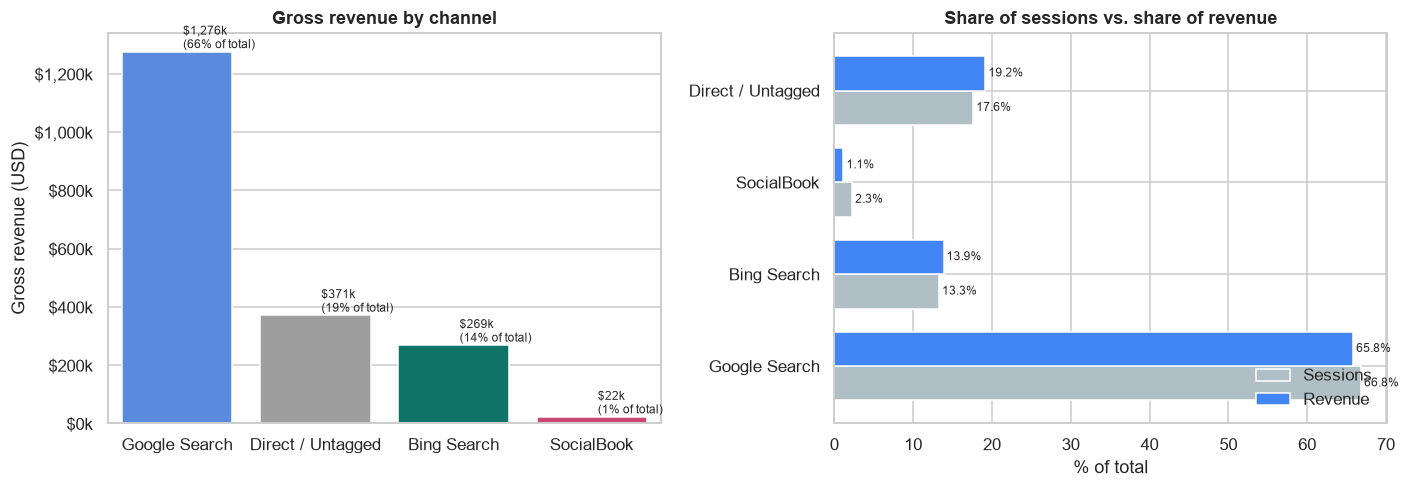

In [9]:
# --- Figure 1: revenue vs. sessions (the core of Q1) -------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

rev = scorecard["gross_revenue_usd"].sort_values(ascending=False)
sns.barplot(x=rev.index, y=rev.values, ax=axes[0],
            hue=rev.index, palette=CHANNEL_COLORS, legend=False)
axes[0].set_title("Gross revenue by channel")
axes[0].set_ylabel("Gross revenue (USD)")
axes[0].set_xlabel("")
axes[0].yaxis.set_major_formatter(USD_K)
for i, v in enumerate(rev.values):
    axes[0].text(i, v, f"  ${v/1000:,.0f}k\n  ({scorecard.loc[rev.index[i],'revenue_share_pct']:.0f}% of total)",
                 ha="left", va="bottom", fontsize=8)

share_mix = pd.DataFrame({
    "Sessions": sessions.channel.value_counts(normalize=True).mul(100),
    "Revenue": scorecard.gross_revenue_usd / scorecard.gross_revenue_usd.sum() * 100,
}).reindex(CHANNEL_ORDER)
share_mix.plot(kind="barh", ax=axes[1], color=["#B0BEC5", "#4285F4"], width=0.75)
axes[1].set_title("Share of sessions vs. share of revenue")
axes[1].set_xlabel("% of total")
axes[1].set_ylabel("")
axes[1].legend(loc="lower right", frameon=False)
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.1f%%", fontsize=8, padding=2)

plt.tight_layout()
plt.savefig(FIG_DIR / "fig1_channel_revenue.png", bbox_inches="tight")
plt.show()

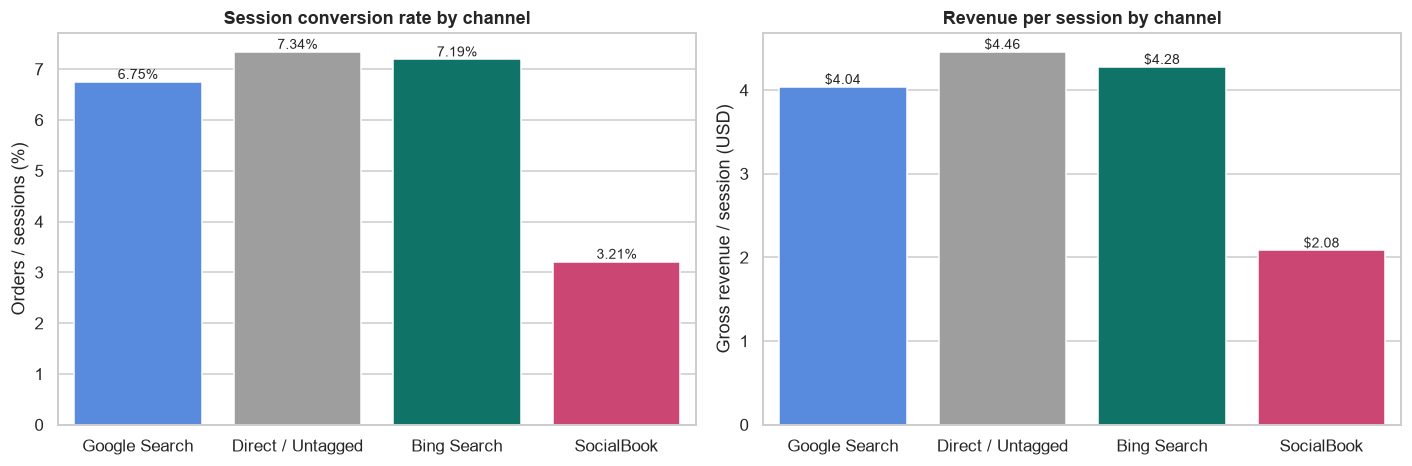

In [10]:
# --- Figure 2: conversion rate and revenue per session -----------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
order_ = scorecard.index.tolist()

sns.barplot(x=scorecard.index, y=scorecard.session_cvr_pct, ax=axes[0],
            hue=scorecard.index, palette=CHANNEL_COLORS, order=order_, legend=False)
axes[0].set_title("Session conversion rate by channel")
axes[0].set_ylabel("Orders / sessions (%)")
axes[0].set_xlabel("")
for i, v in enumerate(scorecard.session_cvr_pct.reindex(order_).values):
    axes[0].text(i, v, f"{v:.2f}%", ha="center", va="bottom", fontsize=9)

sns.barplot(x=scorecard.index, y=scorecard.revenue_per_session_usd, ax=axes[1],
            hue=scorecard.index, palette=CHANNEL_COLORS, order=order_, legend=False)
axes[1].set_title("Revenue per session by channel")
axes[1].set_ylabel("Gross revenue / session (USD)")
axes[1].set_xlabel("")
for i, v in enumerate(scorecard.revenue_per_session_usd.reindex(order_).values):
    axes[1].text(i, v, f"${v:.2f}", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.savefig(FIG_DIR / "fig2_channel_conversion.png", bbox_inches="tight")
plt.show()

In [11]:
# --- Campaign / ad detail ----------------------------------------------------
# sessions come from traffic; orders/revenue come from the order mart.
camp_sessions = (
    sessions.assign(utm_campaign=sessions.utm_campaign.fillna("(untagged)"))
    .groupby(["channel", "utm_campaign"], as_index=False)
    .size().rename(columns={"size": "sessions"})
)
camp_orders = (
    order_mart.assign(utm_campaign=order_mart.utm_campaign.fillna("(untagged)"))
    .groupby(["channel", "utm_campaign"], as_index=False)
    .agg(orders=("order_id", "count"), gross_revenue_usd=("price_usd", "sum"))
)
campaign_table = (
    camp_sessions.merge(camp_orders, on=["channel", "utm_campaign"], how="left")
    .fillna({"orders": 0, "gross_revenue_usd": 0})
)
campaign_table["session_cvr_pct"] = 100 * campaign_table.orders / campaign_table.sessions
campaign_table["aov_usd"] = campaign_table.gross_revenue_usd / campaign_table.orders.replace(0, np.nan)
campaign_table.sort_values("gross_revenue_usd", ascending=False).round(2)

,channel,utm_campaign,sessions,orders,gross_revenue_usd,session_cvr_pct,aov_usd
4,Google Search,nonbrand,282706,18822,"1,124,414.21",6.66,59.74
2,Direct / Untagged,(untagged),83328,6118,"371,433.03",7.34,60.71
1,Bing Search,nonbrand,54909,3818,"225,563.48",6.95,59.08
3,Google Search,brand,33329,2511,"151,730.68",7.53,60.43
0,Bing Search,brand,7914,701,"43,109.02",8.86,61.50
5,SocialBook,desktop_targeted,5590,288,"18,516.10",5.15,64.29
6,SocialBook,pilot,5095,55,"3,743.23",1.08,68.06


### Q1 — Findings

* **Google Search is the business.** It brings **316,035 sessions (66.8% of traffic)** and **\$1.28M in gross
  revenue — 65.8% of the total**, at a **6.75% session conversion rate**.
* **Direct / Untagged is the second engine and the most efficient at the point of sale.** With only 17.6% of
  sessions it produces **19.2% of revenue (\$371k)** and converts best of any large channel at **7.34%**, with the
  highest revenue per session (**\$4.46**). Treat with care: this is returning/bookmark traffic, so it signals
  *brand strength* rather than a media channel you can scale.
* **Bing Search is a small but healthy channel:** 13.9% of revenue, **7.19% CVR**, and revenue per session of
  **\$4.28 — close to direct traffic.** It punches above its session share.
* **SocialBook under-performs badly.** Despite 10,685 sessions it converts at just **3.21%** — less than half
  the other channels — for **1.1% of revenue** and the lowest revenue per session (**\$2.08**). AOV is actually
  the *highest* (\$64.90), so the problem is **traffic quality / intent, not basket size.**
* **AOV is stable (~$59–65) across channels**, so channel differences are driven by **conversion**, not order value.
* Within paid search, **brand terms convert better than non-brand** (Google 7.53% vs 6.66%; Bing **8.86%** vs 6.95%),
  and SocialBook's underperformance is concentrated in its `pilot` campaign (**1.08% CVR**).

<a id="6-q2--first-time-vs-repeat-conversion-by-channel"></a>
## 6. Q2 — Do first-time vs. repeat visitors convert differently by channel?

`is_repeat_session = 1` when the user had a previous session. Comparing conversion of first-time vs. repeat
sessions **within each channel** separates *acquiring new demand* from *harvesting returning demand*.

In [12]:
q2 = (
    sessions.groupby(["channel", "visitor_type"], as_index=False)
    .agg(sessions=("website_session_id", "count"))
    .merge(
        order_mart.groupby(["channel", "visitor_type"], as_index=False)
        .agg(orders=("order_id", "count"), gross_revenue_usd=("price_usd", "sum")),
        on=["channel", "visitor_type"], how="left",
    )
    .fillna({"orders": 0, "gross_revenue_usd": 0})
)
q2["session_cvr_pct"] = 100 * q2.orders / q2.sessions
q2["revenue_per_session_usd"] = q2.gross_revenue_usd / q2.sessions
q2["aov_usd"] = q2.gross_revenue_usd / q2.orders.replace(0, np.nan)
q2.sort_values(["channel", "visitor_type"]).round(2)

,channel,visitor_type,sessions,orders,gross_revenue_usd,session_cvr_pct,revenue_per_session_usd,aov_usd
0,Bing Search,First-time,57802,4061,"240,594.36",7.03,4.16,59.25
1,Bing Search,Repeat,5021,458,"28,078.14",9.12,5.59,61.31
2,Direct / Untagged,First-time,30999,2110,"128,791.32",6.81,4.15,61.04
3,Direct / Untagged,Repeat,52329,4008,"242,641.71",7.66,4.64,60.54
4,Google Search,First-time,294832,19650,"1,174,629.91",6.66,3.98,59.78
5,Google Search,Repeat,21203,1683,"101,514.98",7.94,4.79,60.32
6,SocialBook,First-time,10685,343,"22,259.33",3.21,2.08,64.90


In [13]:
# --- Conversion lift table ---------------------------------------------------
lift = q2.pivot(index="channel", columns="visitor_type",
                values="session_cvr_pct").reindex(CHANNEL_ORDER)
lift["lift_pp"] = lift["Repeat"] - lift["First-time"]
lift["lift_pct_relative"] = 100 * (lift["Repeat"] / lift["First-time"] - 1)
mix = (sessions.assign(is_repeat=(sessions.visitor_type == "Repeat").astype(int))
       .groupby("channel").is_repeat.mean().mul(100).rename("repeat_session_mix_pct"))
lift = lift.join(mix).round(2)
lift

,First-time,Repeat,lift_pp,lift_pct_relative,repeat_session_mix_pct
channel,,,,,
Google Search,6.66,7.94,1.27,19.10,6.71
Bing Search,7.03,9.12,2.10,29.83,7.99
SocialBook,3.21,NaN,NaN,NaN,0.00
Direct / Untagged,6.81,7.66,0.85,12.53,62.80


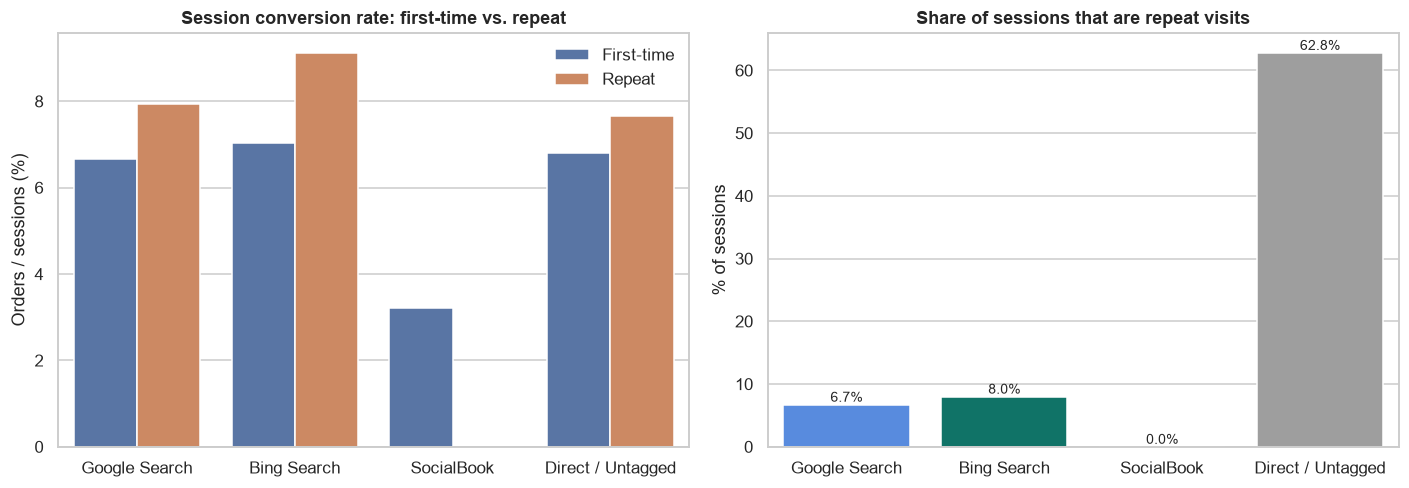

In [14]:
# --- Figure 3: new vs repeat conversion by channel ---------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

plot_df = q2[q2.channel.isin(CHANNEL_ORDER)]
sns.barplot(data=plot_df, x="channel", y="session_cvr_pct", hue="visitor_type",
            order=CHANNEL_ORDER, hue_order=["First-time", "Repeat"],
            palette=VISITOR_COLORS, ax=axes[0])
axes[0].set_title("Session conversion rate: first-time vs. repeat")
axes[0].set_ylabel("Orders / sessions (%)")
axes[0].set_xlabel("")
axes[0].legend(title="", frameon=False)

# repeat mix drives the story on the right
sns.barplot(x=mix.index, y=mix.values, ax=axes[1],
            hue=mix.index, palette=CHANNEL_COLORS, order=CHANNEL_ORDER, legend=False)
axes[1].set_title("Share of sessions that are repeat visits")
axes[1].set_ylabel("% of sessions")
axes[1].set_xlabel("")
for i, v in enumerate(mix.reindex(CHANNEL_ORDER).values):
    axes[1].text(i, v, f"{v:.1f}%", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.savefig(FIG_DIR / "fig3_new_vs_repeat.png", bbox_inches="tight")
plt.show()

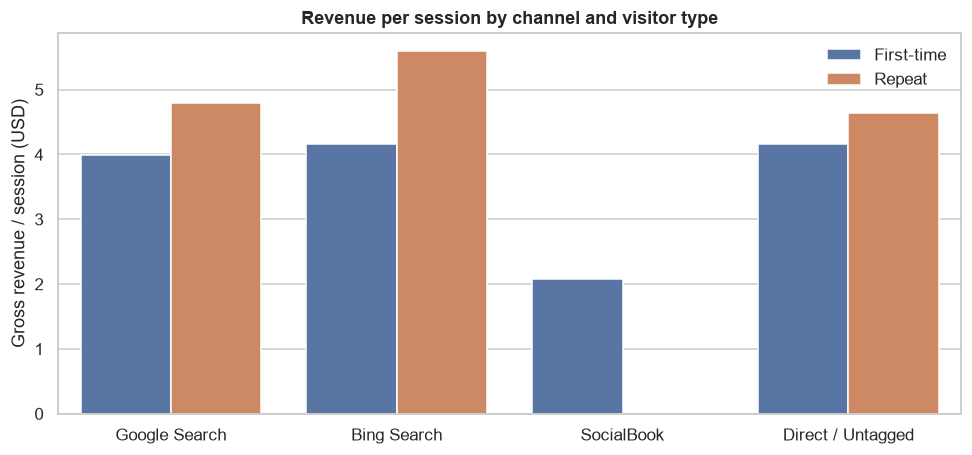

In [15]:
# --- Figure 4: revenue per session by channel and visitor type ---------------
fig, ax = plt.subplots(figsize=(9, 4.3))
sns.barplot(data=plot_df, x="channel", y="revenue_per_session_usd", hue="visitor_type",
            order=CHANNEL_ORDER, hue_order=["First-time", "Repeat"],
            palette=VISITOR_COLORS, ax=ax)
ax.set_title("Revenue per session by channel and visitor type")
ax.set_ylabel("Gross revenue / session (USD)")
ax.set_xlabel("")
ax.legend(title="", frameon=False)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig4_revenue_per_session.png", bbox_inches="tight")
plt.show()

### Q2 — Findings

* **Repeat visitors convert better in every channel that has them.** The lift is consistent, which makes it a
  structural effect (returning users already know the brand and the checkout) rather than noise:

| Channel | First-time CVR | Repeat CVR | Lift |
|---|---|---|---|
| Bing Search | 7.03% | **9.12%** | +2.10 pp (+30% relative) |
| Google Search | 6.66% | **7.94%** | +1.27 pp (+19% relative) |
| Direct / Untagged | 6.81% | **7.66%** | +0.85 pp (+13% relative) |
| SocialBook | 3.21% | *no repeat sessions* | — |

* **The channel mix of "repeat" traffic tells the real story.** Direct/Untagged is **62.8% repeat sessions**,
  while Google Search is only **6.7%** and Bing 8.0%. In other words, **Google and Bing are genuine *acquisition*
  channels**; direct/untagged is largely *retention* traffic. This is exactly why direct traffic's high CVR should
  not be read as media efficiency.
* **SocialBook acquires first-time visitors only — and they convert at 3.21%.** It builds no returning base in the
  data, so it neither acquires well nor retains. This strengthens the case to cut or restructure it.
* **Monetization of repeat visits is higher too:** repeat revenue per session beats first-time in every channel
  (e.g. Bing **\$5.59** vs **\$4.16**; Google **\$4.79** vs **\$3.98**).

**So: does the answer to Q2 change how we read Q1? Yes.** A channel's headline CVR partly reflects *how much
returning traffic it carries*. Rank channels by **first-time conversion** for an honest acquisition comparison —
and on that basis Bing (7.03%) and Google (6.66%) are close, while SocialBook (3.21%) is clearly unprofitable
to keep funding as-is.

<a id="7-supporting-analysis-funnel-device-campaign-trends"></a>
## 7. Supporting analysis (funnel, device, campaign, trends)

In [16]:
# --- Session-level funnel ----------------------------------------------------
def pageview_step(url: str):
    if url == "/home" or url.startswith("/lander-"):
        return "1_lander"
    if url == "/products" or url.startswith("/the-"):
        return "2_product"
    if url == "/cart":
        return "3_cart"
    if url == "/shipping":
        return "4_shipping"
    if url.startswith("/billing"):
        return "5_billing"
    if url == "/thank-you-for-your-order":
        return "6_thankyou"
    return None

steps = website_pageviews.assign(step=website_pageviews.pageview_url.map(pageview_step))
reach = (steps.dropna(subset=["step"])
         .groupby(["website_session_id", "step"]).size().unstack(fill_value=0))
reach = (reach > 0).astype(int).join(sessions.set_index("website_session_id")["channel"])

STEP_LABELS = {"1_lander": "Lander / Home", "2_product": "Product page", "3_cart": "Cart",
               "4_shipping": "Shipping", "5_billing": "Billing", "6_thankyou": "Purchase"}
funnel_overall = pd.DataFrame({
    "step": list(STEP_LABELS.values()),
    "sessions": [int(reach[c].sum()) for c in STEP_LABELS],
})
funnel_overall["pct_of_all_sessions"] = 100 * funnel_overall.sessions / len(sessions)
funnel_overall["step_conversion_pct"] = 100 * funnel_overall.sessions / funnel_overall.sessions.shift(1)
funnel_overall.round(2)

,step,sessions,pct_of_all_sessions,step_conversion_pct
0,Lander / Home,472871,100.00,NaN
1,Product page,261231,55.24,55.24
2,Cart,94953,20.08,36.35
3,Shipping,64484,13.64,67.91
4,Billing,52058,11.01,80.73
5,Purchase,32313,6.83,62.07


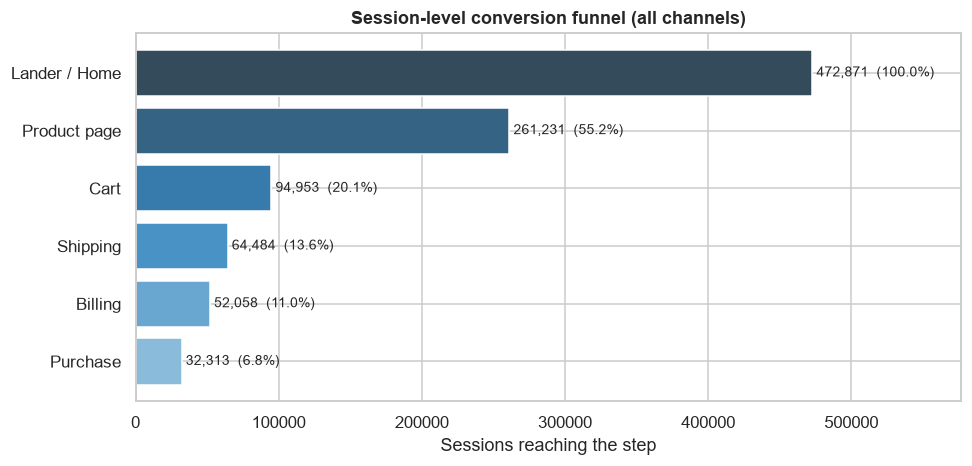

In [17]:
# --- Figure 5: funnel --------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 4.4))
funnel_rev = funnel_overall.iloc[::-1]
bars = ax.barh(funnel_rev.step, funnel_rev.sessions, color=sns.color_palette("Blues_d", len(funnel_rev)))
for bar, v, p in zip(bars, funnel_rev.sessions, funnel_rev.pct_of_all_sessions):
    ax.text(v, bar.get_y() + bar.get_height()/2, f" {v:,.0f}  ({p:.1f}%)",
            va="center", fontsize=9)
ax.set_title("Session-level conversion funnel (all channels)")
ax.set_xlabel("Sessions reaching the step")
ax.set_xlim(0, funnel_overall.sessions.max() * 1.22)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig5_funnel.png", bbox_inches="tight")
plt.show()

In [18]:
# --- Funnel by channel -------------------------------------------------------
funnel_by_channel = pd.DataFrame({
    label: reach.groupby("channel")[key].sum()
    for key, label in [("2_product", "reached_product"), ("3_cart", "reached_cart"),
                       ("4_shipping", "reached_shipping"), ("5_billing", "reached_billing"),
                       ("6_thankyou", "purchased")]
})
funnel_by_channel.insert(0, "sessions", sessions.groupby("channel").size())
funnel_by_channel = funnel_by_channel.reindex(CHANNEL_ORDER)
funnel_by_channel.round(0)

,sessions,reached_product,reached_cart,reached_shipping,reached_billing,purchased
channel,,,,,,
Google Search,316035,175762,63376,42855,34561,21333
Bing Search,62823,32997,12476,8698,7125,4519
SocialBook,10685,2390,950,652,535,343
Direct / Untagged,83328,50082,18151,12279,9837,6118


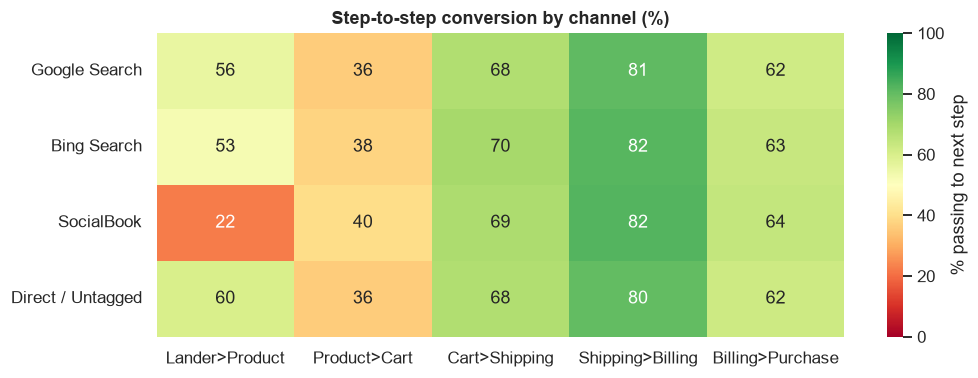

In [19]:
# --- Figure 6: step-to-step conversion heatmap by channel --------------------
rates = pd.DataFrame(index=funnel_by_channel.index)
rates["Lander>Product"] = 100 * funnel_by_channel.reached_product / funnel_by_channel.sessions
rates["Product>Cart"]    = 100 * funnel_by_channel.reached_cart / funnel_by_channel.reached_product
rates["Cart>Shipping"]   = 100 * funnel_by_channel.reached_shipping / funnel_by_channel.reached_cart
rates["Shipping>Billing"]= 100 * funnel_by_channel.reached_billing / funnel_by_channel.reached_shipping
rates["Billing>Purchase"]= 100 * funnel_by_channel.purchased / funnel_by_channel.reached_billing

fig, ax = plt.subplots(figsize=(9.5, 3.6))
sns.heatmap(rates, annot=True, fmt=".0f", cmap="RdYlGn", vmin=0, vmax=100,
            cbar_kws={"label": "% passing to next step"}, ax=ax)
ax.set_title("Step-to-step conversion by channel (%)")
ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig6_funnel_by_channel.png", bbox_inches="tight")
plt.show()

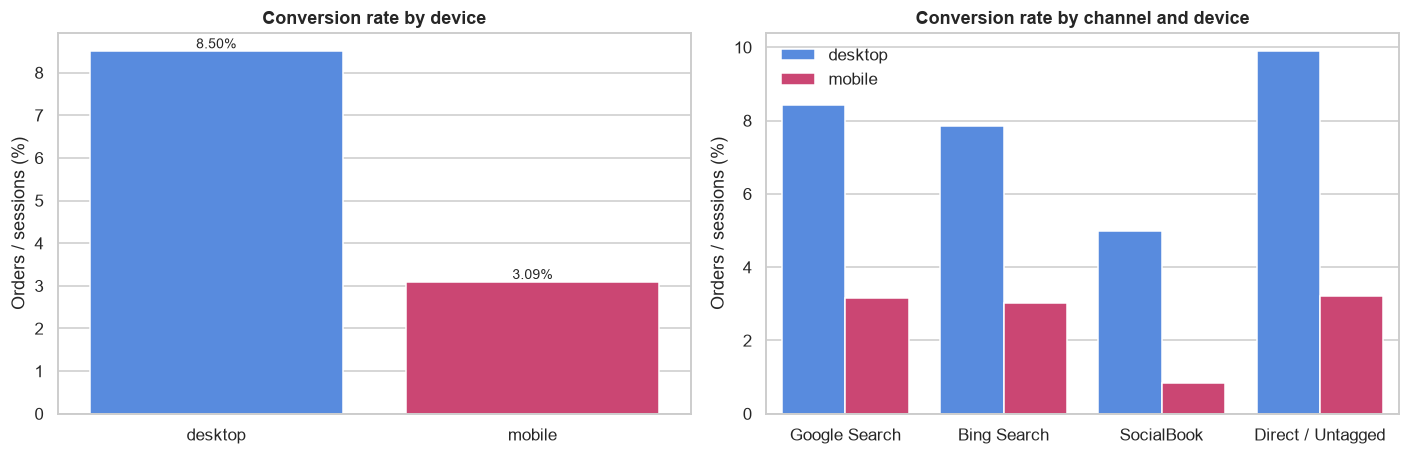

,sessions,orders,gross_revenue_usd,session_cvr_pct,revenue_share_pct
device_type,,,,,
desktop,327027,27805,"1,665,757.84",8.50,85.93
mobile,145844,4508,"272,751.91",3.09,14.07


In [20]:
# --- Device analysis ---------------------------------------------------------
device_table = (
    sessions.groupby("device_type").size().rename("sessions").to_frame()
    .join(order_mart.groupby("device_type").agg(
        orders=("order_id", "count"), gross_revenue_usd=("price_usd", "sum")))
)
device_table["session_cvr_pct"] = 100 * device_table.orders / device_table.sessions
device_table["revenue_share_pct"] = 100 * device_table.gross_revenue_usd / device_table.gross_revenue_usd.sum()

device_channel = (
    sessions.groupby(["channel", "device_type"], as_index=False).size().rename(columns={"size": "sessions"})
    .merge(order_mart.groupby(["channel", "device_type"], as_index=False).agg(orders=("order_id", "count")),
           on=["channel", "device_type"], how="left")
    .fillna({"orders": 0})
)
device_channel["session_cvr_pct"] = 100 * device_channel.orders / device_channel.sessions

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
sns.barplot(data=device_table.reset_index(), x="device_type", y="session_cvr_pct", ax=axes[0],
            hue="device_type", palette={"desktop": "#4285F4", "mobile": "#E1306C"}, legend=False)
axes[0].set_title("Conversion rate by device")
axes[0].set_ylabel("Orders / sessions (%)"); axes[0].set_xlabel("")
for i, v in enumerate(device_table.session_cvr_pct.values):
    axes[0].text(i, v, f"{v:.2f}%", ha="center", va="bottom", fontsize=9)

sns.barplot(data=device_channel, x="channel", y="session_cvr_pct", hue="device_type",
            order=CHANNEL_ORDER, palette={"desktop": "#4285F4", "mobile": "#E1306C"}, ax=axes[1])
axes[1].set_title("Conversion rate by channel and device")
axes[1].set_ylabel("Orders / sessions (%)"); axes[1].set_xlabel("")
axes[1].legend(title="", frameon=False)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig7_device.png", bbox_inches="tight")
plt.show()

device_table.round(2)

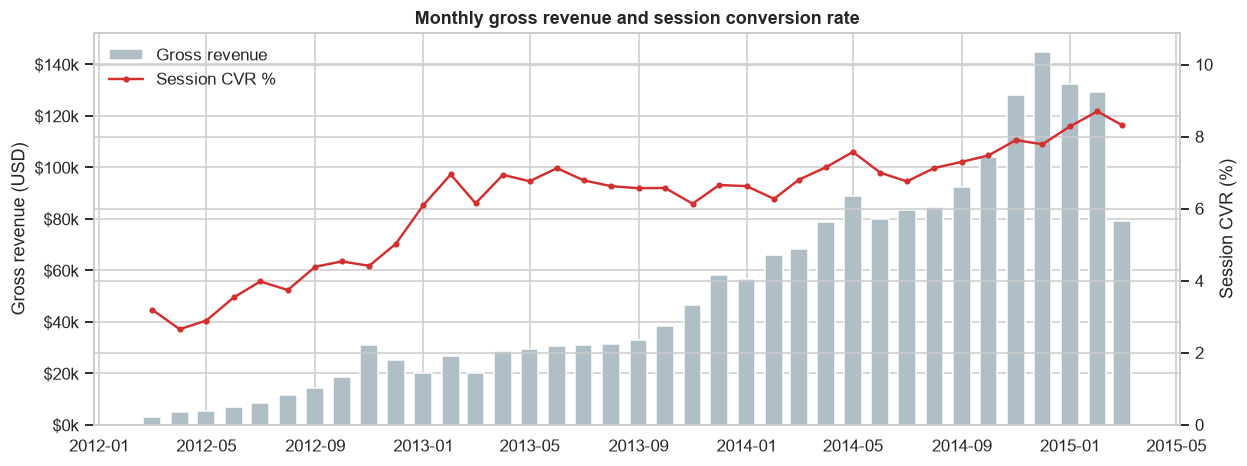

,sessions,orders,gross_revenue_usd,net_revenue_usd,session_cvr_pct
month,,,,,
2014-10-01,21526,1609,"103,905.98","101,134.57",7.47
2014-11-01,25125,1985,"128,162.98","123,945.85",7.90
2014-12-01,29722,2314,"144,823.02","139,484.13",7.79
2015-01-01,25337,2098,"132,211.54","127,422.53",8.28
2015-02-01,23778,2068,"129,212.94","125,443.72",8.70
2015-03-01,15083,1254,"78,951.07","76,257.62",8.31


In [21]:
# --- Monthly trend -----------------------------------------------------------
monthly = (
    sessions.groupby("month").size().rename("sessions").to_frame()
    .join(order_mart.groupby("month").agg(
        orders=("order_id", "count"), gross_revenue_usd=("price_usd", "sum"),
        net_revenue_usd=("net_revenue_usd", "sum")))
    .fillna(0)
)
monthly["session_cvr_pct"] = 100 * monthly.orders / monthly.sessions

fig, ax1 = plt.subplots(figsize=(11.5, 4.4))
ax1.bar(monthly.index, monthly.gross_revenue_usd, color="#B0BEC5", width=20, label="Gross revenue")
ax1.set_ylabel("Gross revenue (USD)"); ax1.yaxis.set_major_formatter(USD_K)
ax1.set_title("Monthly gross revenue and session conversion rate")
ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly.session_cvr_pct, color="#D32F2F", marker="o", ms=3, lw=1.6, label="Session CVR %")
ax2.set_ylabel("Session CVR (%)"); ax2.set_ylim(0, monthly.session_cvr_pct.max() * 1.25)
lines = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax1.legend(lines, ["Gross revenue", "Session CVR %"], loc="upper left", frameon=False)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig8_monthly_trend.png", bbox_inches="tight")
plt.show()

monthly.tail(6).round(2)

In [22]:
# --- Refunds and product mix -------------------------------------------------
refunds_channel = (
    order_mart.groupby("channel").agg(
        orders=("order_id", "count"),
        gross_revenue_usd=("price_usd", "sum"),
        refunds_usd=("refund_amount_usd", "sum"))
)
refunds_channel["refund_rate_pct"] = 100 * refunds_channel.refunds_usd / refunds_channel.gross_revenue_usd

product_table = (
    order_items.assign(gross_margin_usd=order_items.price_usd - order_items.cogs_usd)
    .merge(products, on="product_id")
    .groupby("product_name")
    .agg(units_sold=("order_item_id", "count"),
         gross_revenue_usd=("price_usd", "sum"),
         gross_margin_usd=("gross_margin_usd", "sum"))
)
product_table["revenue_share_pct"] = 100 * product_table.gross_revenue_usd / product_table.gross_revenue_usd.sum()
print("Refunds by channel"); display(refunds_channel.round(2))
print("Product mix"); display(product_table.sort_values("gross_revenue_usd", ascending=False).round(2))

Refunds by channel


,orders,gross_revenue_usd,refunds_usd,refund_rate_pct
channel,,,,
Bing Search,4519,"268,672.50","11,559.65",4.30
Direct / Untagged,6118,"371,433.03","15,692.80",4.22
Google Search,21333,"1,276,144.89","57,054.46",4.47
SocialBook,343,"22,259.33","1,031.78",4.64


Product mix


,units_sold,gross_revenue_usd,gross_margin_usd,revenue_share_pct
product_name,,,,
The Original Mr. Fuzzy,24226,"1,211,057.74","738,893.00",62.47
The Forever Love Bear,5796,"347,702.04","217,350.00",17.94
The Birthday Sugar Panda,4985,"229,260.15","157,027.50",11.83
The Hudson River Mini bear,5018,"150,489.82","102,869.00",7.76


### Supporting-analysis findings

* **The funnel leaks at the top.** Of 472,871 sessions, only **55.2%** ever reach a product page and just
  **20.1%** reach the cart. The single biggest drop-off in the whole journey is **lander → product page**, and
  it is worst for SocialBook (22% vs ~50–60% for search/direct). Fixing the landing experience is the highest-leverage
  conversion lever.
* Cart → shipping → billing is comparatively healthy (68% and 81% step conversion); the billing → purchase step
  at 62% is the second-largest leak and points at payment friction.
* **Desktop converts 8.50% vs mobile 3.09%** — a **2.7×** gap that holds inside *every* channel. Desktop is 86%
  of revenue. Mobile traffic (30.8% of sessions) is being monetised at roughly a third of desktop's rate, so the
  mobile experience is a clear, quantifiable opportunity.
* **Revenue grew ~48×** over three years (from ~\$3.0k in Mar 2012 to a **\$144.8k** peak in Dec 2014) while session
  CVR improved from 3.2% to >8%. Growth is broad-based, not a single spike.
* **Refund rates are uniform (4.2–4.6%)** across channels, so refunds do not explain any channel's performance.
* **The Original Mr. Fuzzy is 62.5% of revenue** — a concentration risk worth naming (single-product dependency).

<a id="8-sql-cross-validation-in-postgresql"></a>
## 8. SQL cross-validation in PostgreSQL

The pandas numbers above are only trustworthy if they survive an independent implementation. I load the same
CSVs into PostgreSQL (`scripts/load_to_postgres.py`, schema in `sql/01_schema.sql`) and recompute the headline
figures in SQL. If pandas and SQL agree, the metrics are real — this is the "trust but verify" step a reviewer
should look for.

The SQL lives in `sql/03_channel_sales.sql` and `sql/04_new_vs_repeat.sql`; the same logic is re-run here.

In [23]:
import psycopg2
from dotenv import load_dotenv
from sqlalchemy import create_engine, text

load_dotenv(PROJECT_ROOT / ".env")
PGPASSWORD = os.getenv("PGPASSWORD") or os.getenv("PG_PASSWORD")
PGUSER = os.getenv("PGUSER", "postgres")
PGHOST = os.getenv("PGHOST", "localhost")
PGPORT = os.getenv("PGPORT", "5432")
PGDATABASE = os.getenv("PGDATABASE", "maven_fuzzy_factory")

engine = None
if PGPASSWORD:
    url = f"postgresql+psycopg2://{PGUSER}:{quote_plus(PGPASSWORD)}@{PGHOST}:{PGPORT}/{PGDATABASE}"
    try:
        engine = create_engine(url)
        with engine.connect() as conn:
            conn.execute(text("SELECT 1"))
        print("connected to PostgreSQL ->", PGDATABASE)
    except Exception as exc:  # pragma: no cover
        print("PostgreSQL unavailable, skipping cross-validation:", exc)
        engine = None
else:
    print("No PG password found (.env) - skipping SQL cross-validation.")

connected to PostgreSQL -> maven_fuzzy_factory


In [24]:
SQL_Q1 = '''
SELECT
    s.channel,
    COUNT(*)                                                AS sessions,
    COUNT(o.order_id)                                       AS orders,
    ROUND(100.0 * COUNT(o.order_id) / COUNT(*), 2)          AS session_cvr_pct,
    ROUND(COALESCE(SUM(o.price_usd), 0), 2)                 AS gross_revenue_usd
FROM v_session_channel s
LEFT JOIN v_order_revenue o USING (website_session_id)
GROUP BY s.channel
ORDER BY gross_revenue_usd DESC;
'''

SQL_Q2 = '''
SELECT
    s.channel,
    COUNT(*) FILTER (WHERE s.is_repeat_session = 0)         AS first_time_sessions,
    COUNT(*) FILTER (WHERE s.is_repeat_session = 1)         AS repeat_sessions,
    ROUND(100.0 * COUNT(*) FILTER (WHERE s.is_repeat_session = 0 AND o.order_id IS NOT NULL)
          / NULLIF(COUNT(*) FILTER (WHERE s.is_repeat_session = 0), 0), 2) AS first_time_cvr_pct,
    ROUND(100.0 * COUNT(*) FILTER (WHERE s.is_repeat_session = 1 AND o.order_id IS NOT NULL)
          / NULLIF(COUNT(*) FILTER (WHERE s.is_repeat_session = 1), 0), 2) AS repeat_cvr_pct
FROM v_session_channel s
LEFT JOIN v_order_revenue o USING (website_session_id)
GROUP BY s.channel
ORDER BY repeat_sessions DESC;
'''

if engine is not None:
    sql_q1 = pd.read_sql(SQL_Q1, engine).set_index("channel")
    sql_q2 = pd.read_sql(SQL_Q2, engine).set_index("channel")
    print("SQL Q1"); display(sql_q1)
    print("SQL Q2 (conversion lift)"); display(sql_q2)
else:
    sql_q1 = sql_q2 = None

SQL Q1


,sessions,orders,session_cvr_pct,gross_revenue_usd
channel,,,,
Google Search,316035,21333,6.75,"1,276,144.89"
Direct / Untagged,83328,6118,7.34,"371,433.03"
Bing Search,62823,4519,7.19,"268,672.50"
SocialBook,10685,343,3.21,"22,259.33"


SQL Q2 (conversion lift)


,first_time_sessions,repeat_sessions,first_time_cvr_pct,repeat_cvr_pct
channel,,,,
Direct / Untagged,30999,52329,6.81,7.66
Google Search,294832,21203,6.66,7.94
Bing Search,57802,5021,7.03,9.12
SocialBook,10685,0,3.21,NaN


In [25]:
# --- Independent recomputation: does SQL == pandas? -------------------------
if engine is not None:
    comparison = pd.DataFrame({
        "pandas_sessions": sessions.groupby("channel").size(),
        "sql_sessions": sql_q1.sessions,
        "pandas_orders": order_mart.groupby("channel").order_id.count(),
        "sql_orders": sql_q1.orders,
        "pandas_cvr_pct": scorecard.session_cvr_pct.round(2),
        "sql_cvr_pct": sql_q1.session_cvr_pct,
        "pandas_revenue": scorecard.gross_revenue_usd.round(2),
        "sql_revenue": sql_q1.gross_revenue_usd,
    })
    comparison["match"] = (
        (comparison.pandas_sessions == comparison.sql_sessions)
        & (comparison.pandas_orders == comparison.sql_orders)
        & np.isclose(comparison.pandas_cvr_pct, comparison.sql_cvr_pct)
        & np.isclose(comparison.pandas_revenue, comparison.sql_revenue)
    )
    print(f"{comparison.match.sum()}/{len(comparison)} channels reconcile exactly between pandas and SQL")
    display(comparison)
else:
    print("Skipped (no database connection).")

4/4 channels reconcile exactly between pandas and SQL


,pandas_sessions,sql_sessions,pandas_orders,sql_orders,pandas_cvr_pct,sql_cvr_pct,pandas_revenue,sql_revenue,match
channel,,,,,,,,,
Bing Search,62823,62823,4519,4519,7.19,7.19,"268,672.50","268,672.50",True
Direct / Untagged,83328,83328,6118,6118,7.34,7.34,"371,433.03","371,433.03",True
Google Search,316035,316035,21333,21333,6.75,6.75,"1,276,144.89","1,276,144.89",True
SocialBook,10685,10685,343,343,3.21,3.21,"22,259.33","22,259.33",True


<a id="9-power-bi-data-model-star-schema"></a>
## 9. Power BI data model (star schema)

The dashboard is built in **Power BI**, so the notebook hands it a proper **star schema** rather than a pile of
flat exports. Everything is written to `powerbi/data/`:

| Table | Type | Grain | Rows |
|---|---|---|---|
| `fact_session_month` | fact | month x channel x device x visitor type | 448 |
| `fact_orders` | fact | one order | 32,313 |
| `fact_order_items` | fact | one order line | 40,025 |
| `fact_funnel` | fact | channel x funnel step | 24 |
| `fact_campaign` | fact | channel x campaign | 7 |
| `fact_product` | fact | product x channel | 16 |
| `dim_date` | dimension | one month | 37 |
| `dim_channel` | dimension | one channel | 4 |
| `dim_device` | dimension | one device | 2 |
| `dim_visitor_type` | dimension | one visitor type | 2 |
| `dim_product` | dimension | one product | 4 |

**Why a star schema.** Conversion needs a *session* denominator while revenue needs an *order* numerator, so the
model keeps both: `fact_session_month` carries sessions **and** orders, making `Orders / Sessions` a valid measure
at any slice, while `fact_orders` and `fact_order_items` provide row-level drill-through detail. Steps to turn
these files into the pictured dashboard are in `powerbi/POWERBI_DASHBOARD_GUIDE.md`.

In [26]:
# --- Power BI data model (star schema) ---------------------------------------
EXPORT_DIR = PROJECT_ROOT / "powerbi" / "data"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

# --- Dimensions --------------------------------------------------------------
dim_date = pd.DataFrame({"month_start": pd.date_range(
    sessions.month.min(), sessions.month.max(), freq="MS")})
dim_date["year"] = dim_date.month_start.dt.year
dim_date["quarter"] = "Q" + dim_date.month_start.dt.quarter.astype(str)
dim_date["month_number"] = dim_date.month_start.dt.month
dim_date["month_name"] = dim_date.month_start.dt.strftime("%b")
dim_date["year_month"] = dim_date.month_start.dt.strftime("%Y-%m")
dim_date["month_label"] = dim_date.month_start.dt.strftime("%b %Y")

dim_channel = pd.DataFrame([
    (1, "Google Search", "Paid Search"),
    (2, "Bing Search", "Paid Search"),
    (3, "SocialBook", "Paid Social"),
    (4, "Direct / Untagged", "Direct"),
], columns=["channel_id", "channel", "channel_group"])
dim_device = pd.DataFrame([(1, "desktop"), (2, "mobile")], columns=["device_id", "device_type"])
dim_visitor_type = pd.DataFrame([(1, "First-time"), (2, "Repeat")], columns=["visitor_type_id", "visitor_type"])
dim_product = products[["product_id", "product_name"]].copy()

ch_map = dict(zip(dim_channel.channel, dim_channel.channel_id))
dev_map = dict(zip(dim_device.device_type, dim_device.device_id))
vt_map = dict(zip(dim_visitor_type.visitor_type, dim_visitor_type.visitor_type_id))

# --- Fact: session-month (drives conversion + revenue at any slice) ----------
sess_agg = (sessions.groupby(["month", "channel", "visitor_type", "device_type"], as_index=False)
            .size().rename(columns={"size": "sessions"}))
order_agg = (order_mart.groupby(["month", "channel", "visitor_type", "device_type"], as_index=False)
             .agg(orders=("order_id", "count"),
                  gross_revenue_usd=("price_usd", "sum"),
                  net_revenue_usd=("net_revenue_usd", "sum"),
                  gross_margin_usd=("gross_margin_usd", "sum"),
                  refund_amount_usd=("refund_amount_usd", "sum")))
fact_session_month = (sess_agg.merge(order_agg, on=["month", "channel", "visitor_type", "device_type"], how="left")
                      .fillna({"orders": 0, "gross_revenue_usd": 0, "net_revenue_usd": 0,
                               "gross_margin_usd": 0, "refund_amount_usd": 0})
                      .rename(columns={"month": "month_start"}))
fact_session_month["channel_id"] = fact_session_month.channel.map(ch_map)
fact_session_month["device_id"] = fact_session_month.device_type.map(dev_map)
fact_session_month["visitor_type_id"] = fact_session_month.visitor_type.map(vt_map)
fact_session_month = fact_session_month[["month_start", "channel_id", "device_id", "visitor_type_id",
                                         "sessions", "orders", "gross_revenue_usd", "net_revenue_usd",
                                         "gross_margin_usd", "refund_amount_usd"]]

# --- Fact: orders (order grain, for drill-through) ---------------------------
fact_orders = order_mart.assign(
    order_date=order_mart.created_at.dt.normalize(),
    month_start=order_mart.month,
    channel_id=order_mart.channel.map(ch_map),
    device_id=order_mart.device_type.map(dev_map),
    visitor_type_id=order_mart.visitor_type.map(vt_map),
    product_id=order_mart.primary_product_id,
)[["order_id", "order_date", "month_start", "website_session_id", "user_id",
   "channel_id", "device_id", "visitor_type_id", "product_id", "utm_campaign", "utm_content",
   "items_purchased", "price_usd", "cogs_usd", "gross_margin_usd", "refund_amount_usd", "net_revenue_usd"]]

# --- Fact: order items (product grain) ---------------------------------------
oi = order_items.merge(order_mart[["order_id", "channel", "month"]], on="order_id", how="left")
oi["channel_id"] = oi.channel.map(ch_map)
oi["month_start"] = oi["month"]
oi["gross_margin_usd"] = oi.price_usd - oi.cogs_usd
fact_order_items = oi[["order_item_id", "order_id", "month_start", "product_id", "channel_id",
                       "is_primary_item", "price_usd", "cogs_usd", "gross_margin_usd"]]

# --- Fact: funnel (per channel x step; totals come from aggregation) ---------
STEP_COLS = {"sessions": "Lander / Home", "reached_product": "Product page", "reached_cart": "Cart",
             "reached_shipping": "Shipping", "reached_billing": "Billing", "purchased": "Purchase"}
funnel_long = (funnel_by_channel.reset_index()
               .melt(id_vars="channel", value_vars=list(STEP_COLS), var_name="col", value_name="sessions_reached"))
funnel_long["funnel_step"] = funnel_long.col.map(STEP_COLS)
funnel_long["step_order"] = funnel_long.funnel_step.map({v: i + 1 for i, v in enumerate(STEP_COLS.values())})
funnel_long["channel_id"] = funnel_long.channel.map(ch_map)
fact_funnel = funnel_long[["channel_id", "step_order", "funnel_step", "sessions_reached"]]

# --- Fact: campaign (channel x campaign) -------------------------------------
fact_campaign = campaign_table.assign(channel_id=campaign_table.channel.map(ch_map))
fact_campaign = fact_campaign[["channel_id", "utm_campaign", "sessions", "orders",
                               "gross_revenue_usd", "session_cvr_pct", "aov_usd"]]

# --- Fact: product performance (product x channel) ---------------------------
fact_product = (fact_order_items.groupby(["product_id", "channel_id"], as_index=False)
                .agg(units_sold=("order_item_id", "count"),
                     gross_revenue_usd=("price_usd", "sum"),
                     gross_margin_usd=("gross_margin_usd", "sum")))

model = {
    "dim_date.csv": dim_date, "dim_channel.csv": dim_channel, "dim_device.csv": dim_device,
    "dim_visitor_type.csv": dim_visitor_type, "dim_product.csv": dim_product,
    "fact_session_month.csv": fact_session_month, "fact_orders.csv": fact_orders,
    "fact_order_items.csv": fact_order_items, "fact_funnel.csv": fact_funnel,
    "fact_campaign.csv": fact_campaign, "fact_product.csv": fact_product,
}
for name, df in model.items():
    df.to_csv(EXPORT_DIR / name, index=False)
    print(f"  {name:<26} {len(df):>9,} rows")
print(f"\n{len(model)} tables written to {EXPORT_DIR}")

  dim_date.csv                      37 rows
  dim_channel.csv                    4 rows
  dim_device.csv                     2 rows
  dim_visitor_type.csv               2 rows
  dim_product.csv                    4 rows
  fact_session_month.csv           448 rows


  fact_orders.csv               32,313 rows
  fact_order_items.csv          40,025 rows
  fact_funnel.csv                   24 rows
  fact_campaign.csv                  7 rows
  fact_product.csv                  16 rows

11 tables written to C:\Users\synth\OneDrive\Documents\kilo\powerbi\data


<a id="10-executive-summary--recommendations"></a>
## 10. Executive summary & recommendations

**Dataset:** 472,871 sessions · 32,313 orders · **\$1,938,509.75** gross revenue · **\$1,853,171.06** net of refunds ·
4 products · Mar 2012 – Mar 2015.

### The two headline answers
1. **Which channels drive sales?** **Google Search** drives the business (65.8% of revenue), with
   **Direct/Untagged** (19.2%, mostly returning traffic) and **Bing Search** (13.9%) behind it.
   **SocialBook is 1.1% of revenue and converts at half the rate of everything else.**
2. **Do first-time vs. repeat visitors convert differently by channel?** **Yes — repeat visitors convert higher
   in every channel that has them** (Bing +2.1 pp, Google +1.3 pp, Direct +0.9 pp). Crucially, channels differ
   enormously in **how much repeat traffic they carry** (direct 62.8% vs Google 6.7%), so headline CVR conflates
   *acquisition* with *retention*.

### Recommendations
1. **Fix SocialBook or stop paying for it.** 3.21% CVR, 1.1% of revenue, zero returning base, and the worst
   funnel entry (only 22% reach a product page). Either restructure the creative/targeting or reallocate the
   budget to Bing, which converts at more than double the rate.
2. **Invest in mobile.** Mobile is 30.8% of sessions but converts at 3.09% vs desktop's 8.50% — a 2.7× gap that
   holds in every channel. Closing even part of it is the largest single upside in the data.
3. **Treat direct/untagged as a brand-health metric, not a media channel.** It is 62.8% repeat traffic; its high
   CVR reflects loyalty, so do not credit it as efficient acquisition.
4. **Protect and grow Bing.** Near-direct efficiency (\$4.28 revenue/session) at a fraction of Google's volume
   suggests headroom to scale the same non-brand strategy.
5. **Prioritise the lander → product-page leak** (44.8% of sessions drop here) and the billing → purchase step.
   These are site-conversion wins that lift *every* channel at once.
6. **De-risk product concentration.** One product is 62.5% of revenue.

### What makes this analysis defensible
* A documented **QA gate** (15 checks) before any metric is computed.
* A **single channel definition** shared by pandas, SQL, and Power BI.
* **Independent recomputation in PostgreSQL** — pandas and SQL reconcile exactly on every channel.
* Explicit handling and labelling of **untagged traffic** rather than silent dropping.

<a id="11-assumptions--limitations"></a>
## 11. Assumptions & limitations

| Assumption / limitation | Impact |
|---|---|
| **Attribution is last-touch at the session level.** An order is credited to the channel of the session that produced it. | Reasonable for this dataset (one order per session), but ignores any earlier touchpoints in the journey. |
| **Untagged sessions are labelled "Direct / Untagged".** | They are mostly returning/bookmark traffic; keeping them visible avoids inflating other channels' CVR, but "direct" is a behaviour, not a purchasable channel. |
| **No cost data.** Only revenue, COGS and refunds are available. | I can rank channels by revenue and margin, but **not by true profit (ROAS/CAC)**. SocialBook's poor conversion is strong evidence of waste, not proof of it. |
| **`is_repeat_session` is session-level, not user-level.** Users with no UTM in their first session appear as "direct". | Directionally correct; a user-level cohort model would sharpen the acquisition-vs-retention split. |
| **Refunds are attributed to the order's channel.** | Fine here because refund rates are uniform (4.2–4.6%) across channels. |
| **Funnels are "session reached step", not strict ordered sequences.** | A session that hits /cart without a product page still counts; standard for this dataset, but slightly optimistic for late stages. |
| **Practice dataset.** Structure and magnitudes are realistic but the company is fictional. | Conclusions demonstrate method; they are not a real client's results. |

In [27]:
import sys, matplotlib, seaborn, sqlalchemy
print("Environment")
print("  python      :", sys.version.split()[0])
print("  pandas      :", pd.__version__)
print("  numpy       :", np.__version__)
print("  matplotlib  :", matplotlib.__version__)
print("  seaborn     :", seaborn.__version__)
print("  sqlalchemy  :", sqlalchemy.__version__)
print("  date range  :", sessions.created_at.min().date(), "->", sessions.created_at.max().date())

Environment
  python      : 3.13.16
  pandas      : 3.0.6
  numpy       : 2.5.3
  matplotlib  : 3.11.2
  seaborn     : 0.13.2
  sqlalchemy  : 2.1.8
  date range  : 2012-03-19 -> 2015-03-19
